# AskAuto - Interview Guide

**How to explain this project clearly, from a 30-second pitch to the hard follow-up questions.**

Read it top to bottom once. Before an interview, re-read the pitch, the diagrams and the
questions at the end. Every number here comes from a real run of this repository.

| Section | Use it for |
|---|---|
| 1. The pitch | "Tell me about a project you built" |
| 2. The big picture | Drawing the architecture on a whiteboard |
| 3. One question, end to end | "Walk me through what happens when..." |
| 4. Design decisions | "Why did you choose X?" |
| 5. Safety | "How do you stop the LLM doing something bad?" |
| 6. Results | "How do you know it works?" |
| 7. What went wrong | "Tell me about a hard bug" |
| 8. Limits and next steps | "What would you do with more time?" |
| 9. Interview questions | Practice answers |
| 10. Glossary | Terms to use confidently |

In [ ]:
from IPython.display import SVG, display

STYLE = """<style>
  .bx  { fill:#f6f8fa; stroke:#d0d7de; stroke-width:1; }
  .bxa { fill:#f3f0ff; stroke:#8b7fd4; stroke-width:1; }
  .bxw { fill:#fff8e6; stroke:#d4a72c; stroke-width:1; }
  .bxg { fill:#eaf7ee; stroke:#3fb950; stroke-width:1; }
  .th  { font:600 13px -apple-system,Segoe UI,Helvetica,sans-serif; fill:#1f2328; }
  .ts  { font:400 11px -apple-system,Segoe UI,Helvetica,sans-serif; fill:#656d76; }
  .tl  { font:600 11px -apple-system,Segoe UI,Helvetica,sans-serif; fill:#8250df;
         letter-spacing:.06em; }
  .arr { stroke:#656d76; stroke-width:1.4; fill:none; }
  .arrR{ stroke:#d1242f; stroke-width:1.6; fill:none; stroke-dasharray:5 3; }
  .lbl { font:400 10px -apple-system,Segoe UI,Helvetica,sans-serif; fill:#d1242f; }
</style>
<defs>
  <marker id="a" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6"
          markerHeight="6" orient="auto-start-reverse">
    <path d="M2 1L8 5L2 9" fill="none" stroke="#656d76" stroke-width="1.5"
          stroke-linecap="round" stroke-linejoin="round"/>
  </marker>
  <marker id="ar" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6"
          markerHeight="6" orient="auto-start-reverse">
    <path d="M2 1L8 5L2 9" fill="none" stroke="#d1242f" stroke-width="1.5"
          stroke-linecap="round" stroke-linejoin="round"/>
  </marker>
</defs>"""

def diagram(body, width=720, height=400):
    """Render a self-contained SVG diagram inline."""
    return SVG(f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" '
               f'height="{height}" viewBox="0 0 {width} {height}">'
               f'{STYLE}{body}</svg>')

## 1. The pitch

### 30 seconds

> I built **AskAuto**, an assistant that answers business questions about a car dealer
> group's sales in plain English. You ask "what was our net revenue last year?", and it
> writes the SQL, runs it safely, and answers - **showing the SQL and the rows behind every
> number**. It refuses questions the data can't answer, asks for clarification when a
> question is vague, and checks that every figure in its answer really came from the data.

### 2 minutes

**The problem.** Managers want numbers but can't write SQL. Plain "text-to-SQL" with an
LLM is risky: it can produce numbers that *look* right but are wrong. This database has two
such traps planted on purpose - revenue must subtract discounts, and regions have exact
spellings. A naive system gets both wrong without any error.

**The approach.**
1. A **metadata catalogue** - descriptions, a business glossary, exact allowed values - is
   stored in the database and every prompt is built from it. That is what defeats the traps.
2. A **LangGraph agent** splits the work into small steps: classify the question, write SQL,
   validate it, run it, write the answer, verify the answer. When a step fails it goes
   *back* - for example, a bad query is retried with the error message as feedback.
3. An **MCP server** is the only component allowed to touch the database. It validates every
   query on the parsed syntax tree (not with string matching), opens the DB read-only, and
   enforces a timeout and row cap.

**The result.** About 2-4 seconds per question, both traps handled, refusals and
clarifications working, and a 25-question golden test set with reference SQL to prove it.

## 2. The big picture

Four runtime pieces and one build step. The key rule: **only the MCP server opens the
database at runtime.** Everything else reaches data through it.

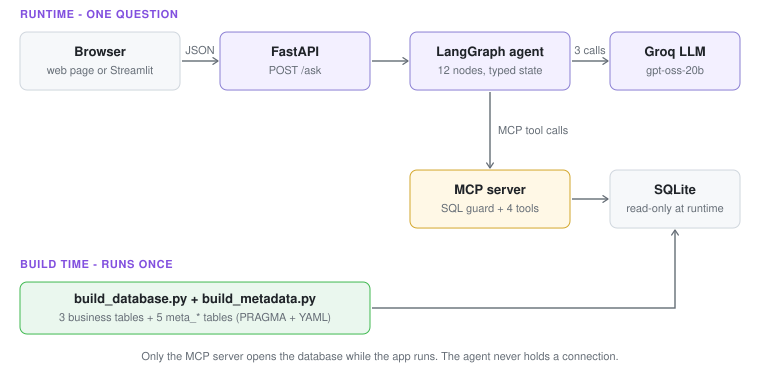

In [1]:
diagram("""
<text class="tl" x="20" y="18" text-anchor="start">RUNTIME - ONE QUESTION</text>
<rect x="20" y="32" width="160" height="58" rx="7" class="bx"/><text class="th" x="100" y="56" text-anchor="middle">Browser</text><text class="ts" x="100" y="74" text-anchor="middle">web page or Streamlit</text>
<rect x="220" y="32" width="150" height="58" rx="7" class="bxa"/><text class="th" x="295" y="56" text-anchor="middle">FastAPI</text><text class="ts" x="295" y="74" text-anchor="middle">POST /ask</text>
<rect x="410" y="32" width="160" height="58" rx="7" class="bxa"/><text class="th" x="490" y="56" text-anchor="middle">LangGraph agent</text><text class="ts" x="490" y="74" text-anchor="middle">12 nodes, typed state</text>
<rect x="610" y="32" width="130" height="58" rx="7" class="bxa"/><text class="th" x="675" y="56" text-anchor="middle">Groq LLM</text><text class="ts" x="675" y="74" text-anchor="middle">gpt-oss-20b</text>
<path d="M182 61 L218 61" class="arr" marker-end="url(#a)"/>
<path d="M372 61 L408 61" class="arr" marker-end="url(#a)"/>
<path d="M572 61 L608 61" class="arr" marker-end="url(#a)"/>
<text class="ts" x="200" y="54" text-anchor="middle">JSON</text>
<text class="ts" x="590" y="54" text-anchor="middle">3 calls</text>
<rect x="410" y="170" width="160" height="58" rx="7" class="bxw"/><text class="th" x="490" y="194" text-anchor="middle">MCP server</text><text class="ts" x="490" y="212" text-anchor="middle">SQL guard + 4 tools</text>
<rect x="610" y="170" width="130" height="58" rx="7" class="bx"/><text class="th" x="675" y="194" text-anchor="middle">SQLite</text><text class="ts" x="675" y="212" text-anchor="middle">read-only at runtime</text>
<path d="M490 92 L490 168" class="arr" marker-end="url(#a)"/>
<path d="M572 199 L608 199" class="arr" marker-end="url(#a)"/>
<text class="ts" x="498" y="134" text-anchor="start">MCP tool calls</text>
<text class="tl" x="20" y="268" text-anchor="start">BUILD TIME - RUNS ONCE</text>
<rect x="20" y="282" width="350" height="52" rx="7" class="bxg"/><text class="th" x="195" y="303" text-anchor="middle">build_database.py + build_metadata.py</text><text class="ts" x="195" y="321" text-anchor="middle">3 business tables + 5 meta_* tables (PRAGMA + YAML)</text>
<path d="M372 308 L675 308 L675 230" class="arr" marker-end="url(#a)"/>
<text class="ts" x="380" y="360" text-anchor="middle">Only the MCP server opens the database while the app runs. The agent never holds a connection.</text>
""", width=760, height=375)

| Piece | Plain-English job | Technology |
|---|---|---|
| Browser | Where you type the question | Plain HTML page at `/`, or Streamlit |
| FastAPI | Receives the question, returns JSON | FastAPI + uvicorn |
| Agent | Decides the steps and retries | LangGraph with one Pydantic state |
| LLM | Classifies, writes SQL, writes the answer | Groq, `openai/gpt-oss-20b` |
| MCP server | The guarded door to the data | MCP Python SDK 2.x, sqlglot, aiosqlite |
| SQLite | 3 business tables + 5 metadata tables | Built by scripts, seeded |

## 3. One question, end to end

"What was our net revenue last year?" goes through eight steps. Three use the LLM, two
use the MCP server, and three are plain Python.

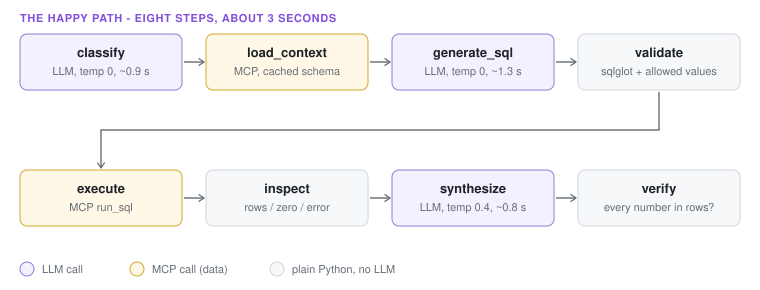

In [2]:
diagram("""
<text class="tl" x="20" y="22" text-anchor="start">THE HAPPY PATH - EIGHT STEPS, ABOUT 3 SECONDS</text>
<rect x="20" y="34" width="162" height="56" rx="7" class="bxa"/><text class="th" x="101" y="57" text-anchor="middle">classify</text><text class="ts" x="101" y="75" text-anchor="middle">LLM, temp 0, ~0.9 s</text>
<rect x="206" y="34" width="162" height="56" rx="7" class="bxw"/><text class="th" x="287" y="57" text-anchor="middle">load_context</text><text class="ts" x="287" y="75" text-anchor="middle">MCP, cached schema</text>
<rect x="392" y="34" width="162" height="56" rx="7" class="bxa"/><text class="th" x="473" y="57" text-anchor="middle">generate_sql</text><text class="ts" x="473" y="75" text-anchor="middle">LLM, temp 0, ~1.3 s</text>
<rect x="578" y="34" width="162" height="56" rx="7" class="bx"/><text class="th" x="659" y="57" text-anchor="middle">validate</text><text class="ts" x="659" y="75" text-anchor="middle">sqlglot + allowed values</text>
<rect x="20" y="170" width="162" height="56" rx="7" class="bxw"/><text class="th" x="101" y="193" text-anchor="middle">execute</text><text class="ts" x="101" y="211" text-anchor="middle">MCP run_sql</text>
<rect x="206" y="170" width="162" height="56" rx="7" class="bx"/><text class="th" x="287" y="193" text-anchor="middle">inspect</text><text class="ts" x="287" y="211" text-anchor="middle">rows / zero / error</text>
<rect x="392" y="170" width="162" height="56" rx="7" class="bxa"/><text class="th" x="473" y="193" text-anchor="middle">synthesize</text><text class="ts" x="473" y="211" text-anchor="middle">LLM, temp 0.4, ~0.8 s</text>
<rect x="578" y="170" width="162" height="56" rx="7" class="bx"/><text class="th" x="659" y="193" text-anchor="middle">verify</text><text class="ts" x="659" y="211" text-anchor="middle">every number in rows?</text>
<path d="M184 62 L204 62" class="arr" marker-end="url(#a)"/>
<path d="M184 198 L204 198" class="arr" marker-end="url(#a)"/>
<path d="M370 62 L390 62" class="arr" marker-end="url(#a)"/>
<path d="M370 198 L390 198" class="arr" marker-end="url(#a)"/>
<path d="M556 62 L576 62" class="arr" marker-end="url(#a)"/>
<path d="M556 198 L576 198" class="arr" marker-end="url(#a)"/>
<path d="M659 92 L659 130 L101 130 L101 168" class="arr" marker-end="url(#a)"/>
<rect x="20" y="262" width="14" height="14" rx="7" class="bxa"/><text class="th" x="27" y="273" text-anchor="middle"></text>
<text class="ts" x="42" y="273" text-anchor="start">LLM call</text>
<rect x="130" y="262" width="14" height="14" rx="7" class="bxw"/><text class="th" x="137" y="273" text-anchor="middle"></text>
<text class="ts" x="152" y="273" text-anchor="start">MCP call (data)</text>
<rect x="270" y="262" width="14" height="14" rx="7" class="bx"/><text class="th" x="277" y="273" text-anchor="middle"></text>
<text class="ts" x="292" y="273" text-anchor="start">plain Python, no LLM</text>
""", width=760, height=290)

| Step | What happens, in plain words | Real example |
|---|---|---|
| classify | Is this answerable, vague, or impossible with this data? | `answerable` |
| load_context | Fetch the data description (cached) | 3 tables, 15 glossary terms |
| generate_sql | LLM writes SQL from the glossary + allowed values | `SUM(sale_price - discount_amount)` for 2025 |
| validate | Parse the SQL: only SELECT, only allowed tables/columns/values | ok |
| execute | MCP server checks again and runs it, read-only | 1 row: `52228431.6` |
| inspect | Rows, zero rows, or an error? | rows |
| synthesize | LLM writes 2-4 sentences using only the row figures | "Net revenue for 2025 was \$52.2M..." |
| verify | Is every number in the answer present in the rows? | `\$52.2M` matches 52,228,431.60 |

When something goes wrong, the graph goes **backwards** instead of crashing:

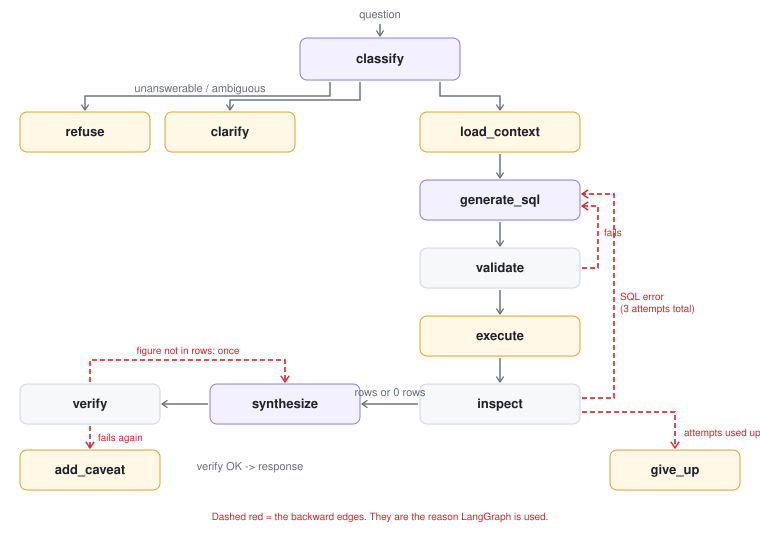

In [3]:
diagram("""
<text class="ts" x="380" y="18" text-anchor="middle">question</text>
<path d="M380 24 L380 36" class="arr" marker-end="url(#a)"/>
<rect x="300" y="38" width="160" height="42" rx="7" class="bxa"/><text class="th" x="380" y="63" text-anchor="middle">classify</text>
<rect x="20" y="112" width="130" height="40" rx="7" class="bxw"/><text class="th" x="85" y="136" text-anchor="middle">refuse</text>
<rect x="165" y="112" width="130" height="40" rx="7" class="bxw"/><text class="th" x="230" y="136" text-anchor="middle">clarify</text>
<path d="M330 82 L330 96 L85 96 L85 110" class="arr" marker-end="url(#a)"/>
<path d="M360 82 L360 100 L230 100 L230 110" class="arr" marker-end="url(#a)"/>
<path d="M440 82 L440 96 L500 96 L500 110" class="arr" marker-end="url(#a)"/>
<text class="ts" x="200" y="92" text-anchor="middle">unanswerable / ambiguous</text>
<rect x="420" y="112" width="160" height="40" rx="7" class="bxw"/><text class="th" x="500" y="136" text-anchor="middle">load_context</text>
<rect x="420" y="180" width="160" height="40" rx="7" class="bxa"/><text class="th" x="500" y="204" text-anchor="middle">generate_sql</text>
<rect x="420" y="248" width="160" height="40" rx="7" class="bx"/><text class="th" x="500" y="272" text-anchor="middle">validate</text>
<rect x="420" y="316" width="160" height="40" rx="7" class="bxw"/><text class="th" x="500" y="340" text-anchor="middle">execute</text>
<rect x="420" y="384" width="160" height="40" rx="7" class="bx"/><text class="th" x="500" y="408" text-anchor="middle">inspect</text>
<path d="M500 154 L500 178" class="arr" marker-end="url(#a)"/>
<path d="M500 222 L500 246" class="arr" marker-end="url(#a)"/>
<path d="M500 290 L500 314" class="arr" marker-end="url(#a)"/>
<path d="M500 358 L500 382" class="arr" marker-end="url(#a)"/>
<path d="M582 268 L598 268 L598 206 L582 206" class="arrR" marker-end="url(#ar)"/>
<path d="M582 398 L614 398 L614 194 L582 194" class="arrR" marker-end="url(#ar)"/>
<text class="lbl" x="604" y="236" text-anchor="start">fails</text>
<text class="lbl" x="620" y="300" text-anchor="start">SQL error</text>
<text class="lbl" x="620" y="312" text-anchor="start">(3 attempts total)</text>
<rect x="610" y="450" width="130" height="40" rx="7" class="bxw"/><text class="th" x="675" y="474" text-anchor="middle">give_up</text>
<path d="M582 412 L675 412 L675 448" class="arrR" marker-end="url(#ar)"/>
<text class="lbl" x="684" y="436" text-anchor="start">attempts used up</text>
<rect x="210" y="384" width="150" height="40" rx="7" class="bxa"/><text class="th" x="285" y="408" text-anchor="middle">synthesize</text>
<rect x="20" y="384" width="140" height="40" rx="7" class="bx"/><text class="th" x="90" y="408" text-anchor="middle">verify</text>
<path d="M418 404 L362 404" class="arr" marker-end="url(#a)"/>
<path d="M208 404 L162 404" class="arr" marker-end="url(#a)"/>
<text class="ts" x="390" y="396" text-anchor="middle">rows or 0 rows</text>
<path d="M90 382 L90 360 L285 360 L285 382" class="arrR" marker-end="url(#ar)"/>
<text class="lbl" x="188" y="354" text-anchor="middle">figure not in rows: once</text>
<rect x="20" y="450" width="140" height="40" rx="7" class="bxw"/><text class="th" x="90" y="474" text-anchor="middle">add_caveat</text>
<path d="M90 426 L90 448" class="arrR" marker-end="url(#ar)"/>
<text class="lbl" x="98" y="441" text-anchor="start">fails again</text>
<text class="ts" x="250" y="470" text-anchor="middle">verify OK -&gt; response</text>
<text class="lbl" x="380" y="520" text-anchor="middle">Dashed red = the backward edges. They are the reason LangGraph is used.</text>
""", width=760, height=535)

| If... | Then... | Limit |
|---|---|---|
| The question is impossible (e.g. credit scores) | `refuse` - says exactly what data is missing | - |
| The question is vague ("best dealer?") | `clarify` - asks which measure you mean | - |
| The SQL fails validation or errors in SQLite | back to `generate_sql` **with the error text** | 3 attempts total |
| All 3 attempts fail | `give_up` - honest message with the last error | - |
| The answer has a number not in the rows | `synthesize` once more, told which number was wrong | 1 retry |
| It fails again | keep the answer, add a caveat naming the number | - |

## 4. Design decisions - and why

Interviewers care more about *why* than *what*. Each decision has a trade-off; saying it
out loud shows judgement.

| Decision | Why | Trade-off |
|---|---|---|
| **Metadata catalogue** in `meta_*` tables; prompts built from it | The traps can only be beaten by knowing what columns *mean*. Stored once, used identically every time | Humans must write and review the YAML |
| **MCP server** as the only DB access | The SQL guard cannot be bypassed; data layer testable alone; swap SQLite for Athena in one module | An extra process and protocol |
| **sqlglot AST validation**, not regex | Regex can be fooled; a parsed tree tells you exactly what the query does | Strict: rare valid SQL may be rejected |
| **Three separate LLM calls** | Each has one job and its own settings (temp 0 for SQL, 0.4 for prose) | 3 round trips instead of 1 |
| **LangGraph** | Retries and refusals are *backward/sideways edges*. Without them, plain functions would do | A dependency to learn |
| **Structured output** - every LLM call returns a Pydantic object | Never parse free text; malformed output is caught immediately | Depends on the provider's JSON-schema support |
| **classify before load_context** | An impossible question costs one cheap call and never touches data | One extra LLM call per question |
| **Deterministic verify** (no LLM) | Catches invented numbers cheaply and reliably | Checks numbers, not claims like "highest" |
| **No vector database** | The whole data description is ~2.1K tokens - it fits in one prompt. Retrieval would add failure modes, not ability | Must change at ~50+ tables (stage 2) |
| **Seeded synthetic data** | Every answer is known in advance, so tests and evals are exact | Not real-world messy data |

## 5. Safety - how a generated query becomes a trusted number

The LLM is treated as untrusted. Six independent layers stand between its SQL and your
answer. Layer 3 is the one that matters: it assumes layers 1 and 2 were bypassed.

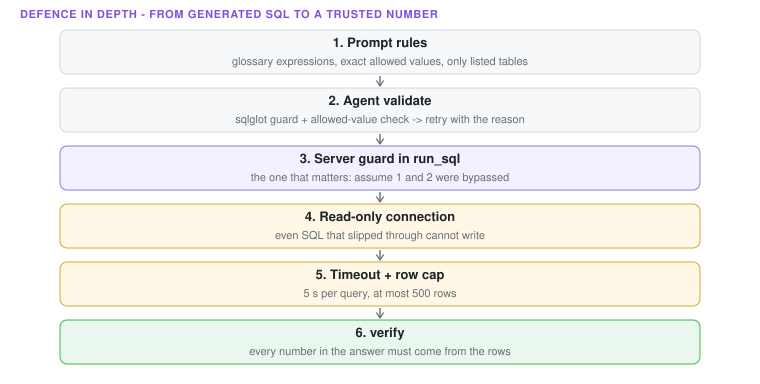

In [4]:
diagram("""
<text class="tl" x="20" y="18" text-anchor="start">DEFENCE IN DEPTH - FROM GENERATED SQL TO A TRUSTED NUMBER</text>
<rect x="60" y="30" width="640" height="44" rx="7" class="bx"/><text class="th" x="380" y="47" text-anchor="middle">1. Prompt rules</text><text class="ts" x="380" y="65" text-anchor="middle">glossary expressions, exact allowed values, only listed tables</text>
<path d="M380 76 L380 86" class="arr" marker-end="url(#a)"/>
<rect x="60" y="88" width="640" height="44" rx="7" class="bx"/><text class="th" x="380" y="105" text-anchor="middle">2. Agent validate</text><text class="ts" x="380" y="123" text-anchor="middle">sqlglot guard + allowed-value check -&gt; retry with the reason</text>
<path d="M380 134 L380 144" class="arr" marker-end="url(#a)"/>
<rect x="60" y="146" width="640" height="44" rx="7" class="bxa"/><text class="th" x="380" y="163" text-anchor="middle">3. Server guard in run_sql</text><text class="ts" x="380" y="181" text-anchor="middle">the one that matters: assume 1 and 2 were bypassed</text>
<path d="M380 192 L380 202" class="arr" marker-end="url(#a)"/>
<rect x="60" y="204" width="640" height="44" rx="7" class="bxw"/><text class="th" x="380" y="221" text-anchor="middle">4. Read-only connection</text><text class="ts" x="380" y="239" text-anchor="middle">even SQL that slipped through cannot write</text>
<path d="M380 250 L380 260" class="arr" marker-end="url(#a)"/>
<rect x="60" y="262" width="640" height="44" rx="7" class="bxw"/><text class="th" x="380" y="279" text-anchor="middle">5. Timeout + row cap</text><text class="ts" x="380" y="297" text-anchor="middle">5 s per query, at most 500 rows</text>
<path d="M380 308 L380 318" class="arr" marker-end="url(#a)"/>
<rect x="60" y="320" width="640" height="44" rx="7" class="bxg"/><text class="th" x="380" y="337" text-anchor="middle">6. verify</text><text class="ts" x="380" y="355" text-anchor="middle">every number in the answer must come from the rows</text>
""", width=760, height=384)

### The two planted traps

Both produce answers that **look right** and raise no error, which makes them the most
dangerous kind of failure.

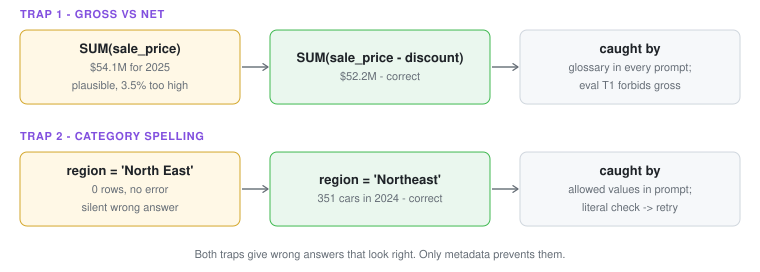

In [5]:
diagram("""
<text class="tl" x="20" y="18" text-anchor="start">TRAP 1 - GROSS VS NET</text>
<rect x="20" y="30" width="220" height="74" rx="7" class="bxw"/><text class="th" x="130" y="53" text-anchor="middle">SUM(sale_price)</text><text class="ts" x="130" y="71" text-anchor="middle">$54.1M for 2025</text><text class="ts" x="130" y="89" text-anchor="middle">plausible, 3.5% too high</text>
<rect x="270" y="30" width="220" height="74" rx="7" class="bxg"/><text class="th" x="380" y="62" text-anchor="middle">SUM(sale_price - discount)</text><text class="ts" x="380" y="80" text-anchor="middle">$52.2M - correct</text>
<rect x="520" y="30" width="220" height="74" rx="7" class="bx"/><text class="th" x="630" y="53" text-anchor="middle">caught by</text><text class="ts" x="630" y="71" text-anchor="middle">glossary in every prompt;</text><text class="ts" x="630" y="89" text-anchor="middle">eval T1 forbids gross</text>
<path d="M242 67 L268 67" class="arr" marker-end="url(#a)"/>
<path d="M492 67 L518 67" class="arr" marker-end="url(#a)"/>
<text class="tl" x="20" y="140" text-anchor="start">TRAP 2 - CATEGORY SPELLING</text>
<rect x="20" y="152" width="220" height="74" rx="7" class="bxw"/><text class="th" x="130" y="175" text-anchor="middle">region = 'North East'</text><text class="ts" x="130" y="193" text-anchor="middle">0 rows, no error</text><text class="ts" x="130" y="211" text-anchor="middle">silent wrong answer</text>
<rect x="270" y="152" width="220" height="74" rx="7" class="bxg"/><text class="th" x="380" y="184" text-anchor="middle">region = 'Northeast'</text><text class="ts" x="380" y="202" text-anchor="middle">351 cars in 2024 - correct</text>
<rect x="520" y="152" width="220" height="74" rx="7" class="bx"/><text class="th" x="630" y="175" text-anchor="middle">caught by</text><text class="ts" x="630" y="193" text-anchor="middle">allowed values in prompt;</text><text class="ts" x="630" y="211" text-anchor="middle">literal check -&gt; retry</text>
<path d="M242 189 L268 189" class="arr" marker-end="url(#a)"/>
<path d="M492 189 L518 189" class="arr" marker-end="url(#a)"/>
<text class="ts" x="380" y="258" text-anchor="middle">Both traps give wrong answers that look right. Only metadata prevents them.</text>
""", width=760, height=272)

## 6. Results - how I know it works

| Check | Result |
|---|---|
| Unit and integration tests | **158 passing**, no network, about 15 seconds |
| Single question latency | **2-4 s** (classify ~0.9 s, SQL ~1.3 s, answer ~0.8 s) |
| Trap 1 (gross vs net) | \$52.2M net for 2025, not \$54.1M gross |
| Trap 2 (spelling) | "North East" -> `'Northeast'`, 351 cars in 2024 |
| Refusal | Credit-score question refused, naming what is missing, in ~0.6 s |
| Data determinism | Full-data fingerprint identical on every rebuild |

Every live answer above was **re-checked with an independent SQL query**, not just trusted.

### Golden evaluation set (25 questions)

In [6]:
import json
from pathlib import Path

root = Path.cwd().parent if Path.cwd().name == "docs" else Path.cwd()
cards = [json.loads(p.read_text(encoding="utf-8"))
         for p in sorted((root / "evals" / "results").glob("*.json"))]
full_runs = [c for c in cards if c["questions"] == 25]   # skip --only subset re-runs
if not full_runs:
    print("No full eval run yet. Run: python evals/run_evals.py")
else:
    card = full_runs[-1]
    print(f"Run:            {card['timestamp']}  (model {card['model']})")
    print(f"Accuracy:       {card['passed']}/{card['questions']} = {card['accuracy']:.0%}")
    print(f"By tier:        {card['by_tier']}")
    print(f"SQL validity:   {card['sql_validity']:.0%} "
          f"(first attempt {card['first_attempt_sql_validity']:.0%})")
    print(f"Latency:        p50 {card['latency_p50_ms']} ms, p95 {card['latency_p95_ms']} ms")
    misses = [o for o in card["outcomes"] if not o["passed"]]
    for o in misses:
        print(f"  miss {o['id']}: {o['question']} -> {'; '.join(o['reasons'])}")

Run:            2026-10-25T13:20:19  (model openai/gpt-oss-20b)
Accuracy:       24/25 = 96%
By tier:        {'lookup': '4/4', 'aggregation': '6/6', 'join': '6/6', 'trap': '3/4', 'refusal': '3/3', 'clarification': '2/2'}
SQL validity:   100% (first attempt 100%)
Latency:        p50 2385 ms, p95 3335 ms
  miss T4: How many F150s have we sold? -> status 'clarification_needed', expected 'answered'; expected value 257.0 not in rows; SQL does not match "'F-150'"


**The one miss, and what it taught.** In the full run, "How many F150s have we sold?"
was classified as *ambiguous* - the classifier wanted a time period. That is wrong: "have
we sold" means all time. The fix was a general rule (a missing time period means all
available data, stated as an assumption), then a targeted re-run: the F-150 question
answered 257, and both genuinely vague questions still asked for clarification. Checking
that the fix didn't break the opposite case is the important part.

### Choosing the model with evidence

I first picked the fastest model from 3 quick runs. A smoke test then showed it looping on
structured output, so I re-tested properly with 10 runs each:

| Model | Garbage output | Avg latency | Worst |
|---|---|---|---|
| `qwen/qwen3.8-27b` | 5 of 10 | 5.7-13.8 s | 24 s |
| **`openai/gpt-oss-20b`** (chosen) | 0 of 10 | 0.55 s | 0.65 s |
| `openai/gpt-oss-120b` | 0 of 10 | 0.75 s | 0.91 s |

**Lesson:** three fast runs looked like a clear winner and weren't. Measure before trusting.

## 7. What went wrong - and what it taught me

These are the best interview stories: a real problem, how it was found, and the lesson.

| Problem | How it was found | Fix | Lesson |
|---|---|---|---|
| Fast model looped inside JSON (`"}]}]}...`) - and still passed validation | Live smoke test | Switched model; capped output tokens; truncated output is an error | Valid format is not a correct answer |
| MCP tool errors lost their message ("Error executing tool") | Throwaway experiment before designing | `run_sql` returns errors **as data**, so retries get the reason | Probe the library before you design |
| `LIMIT` injection replaced the user's smaller limit | Probing sqlglot | Keep the smaller of the two | Read what an API actually does |
| Classifier called "North East" *ambiguous* | Live question | Prompt: spelling variants are not ambiguity | Mocked tests cannot find prompt bugs |
| Vague "column could not be resolved" error | Live join question | Guard names the duplicate column and how to qualify it | Error messages are the retry's input |
| Groq HTTP 400 `json_validate_failed` crashed a question | Burst of live questions | Retry that specific 400 | Classify errors by cause, not status code |
| Random 13-35 s answers | Added retry logging | Found an 8K tokens/min rate limit; pace the evals | Make invisible work visible |
| `/health` always "down" | A test | MCP removed `ping`; health now makes a real tool call | Health checks must touch the real thing |
| "6 MCP processes" | Listed processes with parents | My counting command matched itself | Check your measurement too |
| "How many F150s have we sold?" asked for a time period | The 25-question eval (24/25) | Rule: no time period = all data; re-ran it with the vague questions | Fix one case, re-check the opposite case |

## 8. Limits and next steps

**Honest limits** (say these before the interviewer finds them):

- One question at a time - no follow-up questions or conversation memory.
- The free Groq tier allows about 1.5 questions per minute; bursts slow down.
- verify checks numbers, not claims like "the highest" or "grew".
- The metadata is hand-written, so it must be kept in sync with the data.
- No authentication, row-level security or audit log (deliberately out of scope).

**Growth path** - built so each stage touches as little as possible:

| Stage | Adds | Touches |
|---|---|---|
| 2 | Vector search over the schema, for 50+ tables | `mcp_server/` only + one setting |
| 3 | Retrieve similar worked SQL examples into the prompt | `mcp_server/` only |
| 4 | A free-text column -> supervisor + two specialist agents | the graph shape |

**Production swap** (documented, not built):

| Local | Production | What changes |
|---|---|---|
| SQLite | Athena / Redshift | one module in `mcp_server/` |
| Groq | Bedrock | one class in `providers/` |
| `.env` | Secrets Manager | the settings loader |
| uvicorn | ECS Fargate behind a load balancer | a Dockerfile + task definition |

## 9. Interview questions - with answers

**Why not just give the LLM the schema and let it write SQL?**
Because it produces confident wrong answers. "Revenue" summed as gross is 3.5% too high,
and a misspelt region returns zero rows with no error. The glossary and allowed values fix
both, and validation plus verify catch what slips through.

**Why MCP instead of calling SQLite from a function?**
Four reasons: the guard can't be bypassed; the data layer can be tested with no agent;
swapping databases touches one module; and other tools (like Claude Desktop) can use the
same server.

**How do you stop the LLM from running `DROP TABLE`?**
The server parses every query into a syntax tree and only accepts one SELECT/WITH
statement on three allowed tables. On top of that, the connection is read-only, queries
time out after 5 seconds and return at most 500 rows.

**How does "revenue" mean the same thing every time?**
The glossary maps revenue, turnover, sales value and top line to the *same* SQL
expression, stored once in the database. SQL generation runs at temperature 0, and the
eval set checks it.

**What happens when the generated SQL is wrong?**
The error - from my validator or from SQLite - goes back to the SQL step as feedback. It
gets 3 attempts in total; then it gives up honestly instead of guessing.

**How do you know the numbers in the answer are real?**
A deterministic verify step extracts every number from the answer and checks it appears in
the result rows at the precision written ("\$52.2M" matches 52,228,431.60). If not, the
answer is rewritten once, then shipped with a caveat.

**Why LangGraph?**
Because of the backward edges: retry SQL, re-synthesize, refuse, clarify. A straight
pipeline could be three plain function calls, and then I would remove the dependency.

**Why three LLM calls instead of one?**
Each has one job and different settings. Classification is cheap and stops impossible
questions early. SQL needs temperature 0 and a strict schema. The answer is prose at 0.4.
Lumping them together is what makes naive text-to-SQL brittle.

**Why no vector database?**
Three tables of metadata fit in one prompt, so retrieval would add failure modes without
adding ability. The interface already accepts the question, so adding retrieval later is a
change inside the MCP server only.

**How do you test a system built on an LLM?**
Three layers: unit tests with the LLM mocked to prove the structure; live runs to find
prompt problems the mocks can't; and a golden set of 25 questions whose expected answers
come from reference SQL run against seeded data.

**Does async make it faster?**
Not for one question - the steps are sequential. Async lets the server handle many
questions at once without blocking, which is a different thing.

**What would you change for production?**
Authentication, an audit log of executed SQL, cost limits per query, a managed database,
and a paid LLM tier. The swap table above shows each is a contained change.

**What was the hardest bug?**
The model whose output passed schema validation while being garbage. It taught me that
"valid" and "correct" are different checks, which is why this system has both.

## 10. Glossary

| Term | Plain meaning |
|---|---|
| **Text-to-SQL** | Turning a question in English into a database query |
| **LLM** | Large language model - here, Groq's hosted `gpt-oss-20b` |
| **Temperature** | How random the LLM is. 0 = most repeatable |
| **Structured output** | The LLM must return JSON matching a schema, not free text |
| **Pydantic** | Python library that defines and validates data shapes |
| **MCP** | Model Context Protocol - a standard way for AI apps to call tools |
| **LangGraph** | Library for building step graphs with loops and branches |
| **AST** | Abstract syntax tree - code parsed into a structure you can inspect |
| **sqlglot** | Python SQL parser used to inspect queries safely |
| **Metadata catalogue** | Tables that describe the data: meaning, grain, allowed values |
| **Glossary** | Business term -> exact SQL expression (e.g. net revenue) |
| **Allowed values** | The exact spellings a category column can contain |
| **Grain** | What one row means ("one row per sale") |
| **Golden set** | Questions with known correct answers, used to score the system |
| **p95 latency** | 95% of answers are faster than this |
| **Seeded data** | Generated from a fixed random seed, so identical every run |
| **Lifespan** | FastAPI startup/shutdown hook - opens connections once |
| **Defence in depth** | Several independent safety layers, so one failure isn't fatal |